In [7]:
import gzip
import struct
from pathlib import Path

import numpy as np

# Locate the dataset files
data_dir = Path("../data/fashion_mnist")


def load_images(file_path):
    """Load and validate images from a compressed IDX file."""
    with gzip.open(file_path, "rb") as file:
        header = file.read(16)
        magic, count, rows, cols = struct.unpack(">IIII", header)

        if magic != 2051:
            raise ValueError(f"Invalid image file: {file_path}")

        images = np.frombuffer(file.read(), dtype=np.uint8)
        return images.reshape(count, rows, cols)


def load_labels(file_path):
    """Load and validate labels from a compressed IDX file."""
    with gzip.open(file_path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))

        if magic != 2049:
            raise ValueError(f"Invalid label file: {file_path}")

        labels = np.frombuffer(file.read(), dtype=np.uint8)

        if len(labels) != count:
            raise ValueError("Label count does not match the header.")

        return labels


# Load training and test data
X_train = load_images(data_dir / "train-images-idx3-ubyte.gz")
y_train = load_labels(data_dir / "train-labels-idx1-ubyte.gz")

X_test = load_images(data_dir / "t10k-images-idx3-ubyte.gz")
y_test = load_labels(data_dir / "t10k-labels-idx1-ubyte.gz")

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [8]:
### Prepare Images for Classification

In [9]:
import numpy as np

# Flatten each image into a 784-feature vector
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Training features:", X_train_flat.shape)
print("Test features:", X_test_flat.shape)

Training features: (60000, 784)
Test features: (10000, 784)


### Scale Pixel Values

In [10]:
X_train_scaled = X_train_flat.astype("float32") / 255.0
X_test_scaled = X_test_flat.astype("float32") / 255.0

print("Training pixel range:", X_train_scaled.min(), "to", X_train_scaled.max())
print("Test pixel range:", X_test_scaled.min(), "to", X_test_scaled.max())
print("Training data shape:", X_train_scaled.shape)
print("Test data shape:", X_test_scaled.shape)

Training pixel range: 0.0 to 1.0
Test pixel range: 0.0 to 1.0
Training data shape: (60000, 784)
Test data shape: (10000, 784)


### Train Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

model = LogisticRegression(max_iter=200, random_state=42)

start_time = time.time()
model.fit(X_train_scaled, y_train)
training_time = time.time() - start_time

y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Training time: {training_time:.2f} seconds")

In [ ]:
### Logistic Regression — Baseline Results

| Metric | Result |
|---|---:|
| Model | Logistic Regression |
| Test accuracy | 84.37% |
| Training time | 347.44 seconds |
| Convergence | Not achieved within 200 iterations |

### Train Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import time

model_dt = DecisionTreeClassifier(
    max_depth=20,
    random_state=42
)

start_time = time.time()
model_dt.fit(X_train_flat, y_train)
training_time_dt = time.time() - start_time

y_pred_dt = model_dt.predict(X_test_flat)
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f"Test accuracy: {accuracy_dt:.4f} ({accuracy_dt * 100:.2f}%)")
print(f"Training time: {training_time_dt:.2f} seconds")

### Compare Classification Models

In [ ]:

%pip install pandas

In [6]:
import pandas as pd

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Test Accuracy (%)": 84.37,
        "Training Time (seconds)": 347.44
    },
    {
        "Model": "Decision Tree",
        "Test Accuracy (%)": 79.67,
        "Training Time (seconds)": 21.17
    }
])

results

,Model,Test Accuracy (%),Training Time (seconds)
0,Logistic Regression,84.37,347.44
1,Decision Tree,79.67,21.17


### Train K-Nearest Neighbors

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import time

# Use a subset to keep CPU training and prediction manageable
X_train_knn = X_train_scaled[:15000]
y_train_knn = y_train[:15000]

model_knn = KNeighborsClassifier(n_neighbors=5)

start_time = time.time()
model_knn.fit(X_train_knn, y_train_knn)
training_time_knn = time.time() - start_time

start_time = time.time()
y_pred_knn = model_knn.predict(X_test_scaled)
prediction_time_knn = time.time() - start_time

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"Test accuracy: {accuracy_knn:.4f} ({accuracy_knn * 100:.2f}%)")
print(f"Training time: {training_time_knn:.2f} seconds")
print(f"Prediction time: {prediction_time_knn:.2f} seconds")

Test accuracy: 0.8236 (82.36%)
Training time: 0.01 seconds
Prediction time: 1.21 seconds


### Compare Classification Models

In [12]:
import pandas as pd

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Training Samples": 60000,
        "Test Accuracy (%)": 84.37,
        "Training Time (seconds)": 347.44,
        "Prediction Time (seconds)": None
    },
    {
        "Model": "Decision Tree",
        "Training Samples": 60000,
        "Test Accuracy (%)": 79.67,
        "Training Time (seconds)": 21.17,
        "Prediction Time (seconds)": None
    },
    {
        "Model": "KNN (k=5)",
        "Training Samples": 15000,
        "Test Accuracy (%)": 82.36,
        "Training Time (seconds)": 0.01,
        "Prediction Time (seconds)": 1.21
    }
])

results

,Model,Training Samples,Test Accuracy (%),Training Time (seconds),Prediction Time (seconds)
0,Logistic Regression,60000,84.37,347.44,NaN
1,Decision Tree,60000,79.67,21.17,NaN
2,KNN (k=5),15000,82.36,0.01,1.21


### Analyze Classification Errors

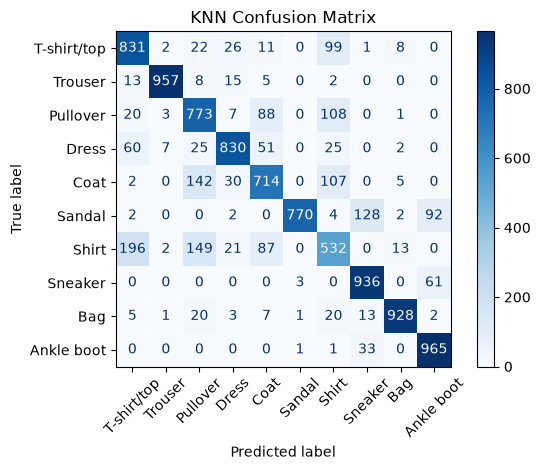

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

### KNN Error Analysis

- KNN achieved 82.36% test accuracy using 15,000 training images.
- Trousers were classified reliably, with 957 of 1,000 images correctly predicted.
- Shirts were frequently confused with T-shirts, pullovers, and coats.
- Coats and pullovers were also commonly confused with each other.
- Low image resolution makes visually similar clothing categories difficult to distinguish.

### Evaluate KNN Performance

In [15]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_knn,
        labels=list(range(10)),
        target_names=class_names,
        digits=3
    )
)

              precision    recall  f1-score   support

 T-shirt/top      0.736     0.831     0.781      1000
     Trouser      0.985     0.957     0.971      1000
    Pullover      0.679     0.773     0.723      1000
       Dress      0.889     0.830     0.858      1000
        Coat      0.741     0.714     0.727      1000
      Sandal      0.994     0.770     0.868      1000
       Shirt      0.592     0.532     0.561      1000
     Sneaker      0.842     0.936     0.887      1000
         Bag      0.968     0.928     0.947      1000
  Ankle boot      0.862     0.965     0.910      1000

    accuracy                          0.824     10000
   macro avg      0.829     0.824     0.823     10000
weighted avg      0.829     0.824     0.823     10000



### KNN Classification Report — Key Findings

- Overall test accuracy: 82.36%.
- Macro F1-score: 0.823.
- Best F1-score: Trouser (0.971).
- Lowest F1-score: Shirt (0.561).
- Bags and trousers are classified reliably.
- Visually similar upper-body garments are frequently confused.
- Sandal has high precision (0.994) but lower recall (0.770).

### Train Random Forest

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import time

model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()
model_rf.fit(X_train_flat, y_train)
training_time_rf = time.time() - start_time

y_pred_rf = model_rf.predict(X_test_flat)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f"Test accuracy: {accuracy_rf:.4f} ({accuracy_rf * 100:.2f}%)")
print(f"Training time: {training_time_rf:.2f} seconds")

Test accuracy: 0.8714 (87.14%)
Training time: 5.31 seconds


### Compare Classification Models

In [18]:
import pandas as pd

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Training Samples": 60000,
        "Accuracy (%)": 84.37,
        "Training Time (s)": 347.44
    },
    {
        "Model": "Decision Tree",
        "Training Samples": 60000,
        "Accuracy (%)": 79.67,
        "Training Time (s)": 21.17
    },
    {
        "Model": "KNN (k=5)",
        "Training Samples": 15000,
        "Accuracy (%)": 82.36,
        "Training Time (s)": 0.01
    },
    {
        "Model": "Random Forest",
        "Training Samples": 60000,
        "Accuracy (%)": 87.14,
        "Training Time (s)": 5.31
    }
])

results.sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)

,Model,Training Samples,Accuracy (%),Training Time (s)
0,Random Forest,60000,87.14,5.31
1,Logistic Regression,60000,84.37,347.44
2,KNN (k=5),15000,82.36,0.01
3,Decision Tree,60000,79.67,21.17


### Evaluate Random Forest

In [19]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_rf,
        labels=list(range(10)),
        target_names=class_names,
        digits=3
    )
)

              precision    recall  f1-score   support

 T-shirt/top      0.817     0.852     0.834      1000
     Trouser      0.996     0.957     0.976      1000
    Pullover      0.759     0.792     0.775      1000
       Dress      0.870     0.903     0.886      1000
        Coat      0.758     0.807     0.782      1000
      Sandal      0.978     0.949     0.963      1000
       Shirt      0.698     0.579     0.633      1000
     Sneaker      0.920     0.952     0.936      1000
         Bag      0.956     0.972     0.964      1000
  Ankle boot      0.953     0.951     0.952      1000

    accuracy                          0.871     10000
   macro avg      0.870     0.871     0.870     10000
weighted avg      0.870     0.871     0.870     10000



### Random Forest — Evaluation Findings

- Test accuracy: 87.14%.
- Macro F1-score: 0.870.
- Best F1-score: Trouser (0.976).
- Lowest F1-score: Shirt (0.633).
- Random Forest achieved higher F1-scores than KNN across all ten categories.
- Visually similar upper-body garments remain the main classification challenge.

### Compare KNN and Random Forest

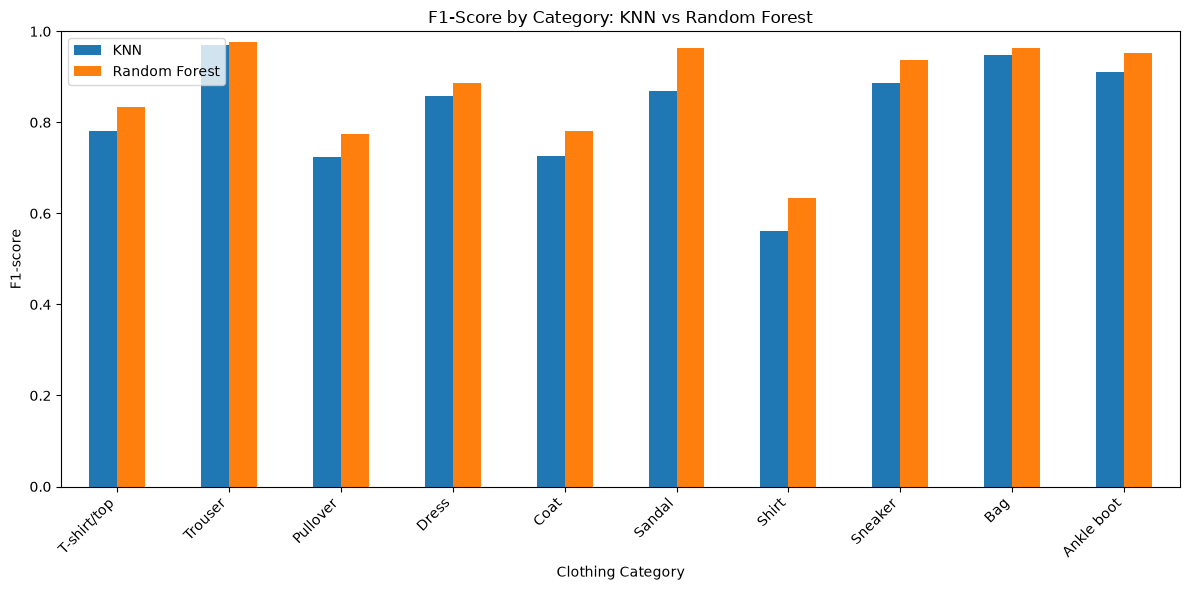

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Category": class_names,
    "KNN": [
        0.781, 0.971, 0.723, 0.858, 0.727,
        0.868, 0.561, 0.887, 0.947, 0.910
    ],
    "Random Forest": [
        0.834, 0.976, 0.775, 0.886, 0.782,
        0.963, 0.633, 0.936, 0.964, 0.952
    ]
})

comparison.set_index("Category").plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("F1-Score by Category: KNN vs Random Forest")
plt.ylabel("F1-score")
plt.xlabel("Clothing Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Classification Experiment Summary

## Classification Summary

Four classification experiments were conducted on Fashion-MNIST.

| Model | Training Samples | Test Accuracy |
|---|---:|---:|
| Logistic Regression | 60,000 | 84.37% |
| Decision Tree | 60,000 | 79.67% |
| KNN (k=5) | 15,000 | 82.36% |
| Random Forest | 60,000 | 87.14% |

### Key Findings

- Random Forest achieved the highest test accuracy at 87.14%.
- Random Forest outperformed KNN in F1-score across all ten categories.
- Shirts were the most challenging category for both models.
- Trousers, bags, and footwear were classified more reliably.
- Logistic Regression was slow to train and did not converge within the configured iteration limit.
- KNN used fewer training samples, so its results are not directly comparable under identical training conditions.

### Conclusion

Random Forest is the current leading classification model among the tested configurations. Further hyperparameter tuning and validation would be needed before treating it as the final model.

### Next Step

Explore unsupervised learning to discover patterns and groups in clothing images without using their labels during clustering.